# DC4 paper Figure 2 — isolated NGC 4151 CPL + PL

Fit the unfluctuated three-month isolated NGC 4151 source plus instrumental background, scaled to 24 months by multiplying source counts, background counts, and livetime by eight. This is an exposure-scaled forecast from the three-month templates, not an independent 24-month event simulation. The CPL index stays fixed at −1.75; CPL normalization and cutoff, PL normalization and index, and background rate are fitted. Multiple starts are ranked by **source TS against the background-only null**; the CPL+PL versus CPL-only ΔTS is calculated separately. The ten-bin SED is fitted separately.


In [16]:
from pathlib import Path
from copy import deepcopy
import sys
import gc
import hashlib

import astropy.units as u
from astropy.coordinates import SkyCoord
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

from astromodels import (
    Cutoff_powerlaw, ExtendedSource, PointSource, Parameter, Powerlaw, Model, load_model,
)
from histpy import Histogram
from threeML import DataList, JointLikelihood, BayesianAnalysis
from threeML.minimizer.minimization import FitFailed, CannotComputeCovariance
from threeML.exceptions.custom_exceptions import BadCovariance
from cosipy.threeml import BinnedSED
from dataclasses import dataclass
from scipy.optimize import brentq, minimize

from cosipy import BinnedData
from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.event_selection import GoodTimeInterval
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.response import (
    BinnedInstrumentResponse,
    BinnedThreeMLModelFolding,
    BinnedThreeMLPointSourceResponse,
    BinnedThreeMLExtendedSourceResponse,
    ExtendedSourceResponse,
)
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.statistics import PoissonLikelihood
from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401


# DC4 recipe interpretation stays in this tutorial; reusable calculations live in cosipy.
import json
import yaml
from astropy.io import fits
from cosipy.response.temporal_profile import LightcurveProfile
from cosipy.response.threeml_temporal_response import (
    ZeroPointSourceResponse, ComponentPointSourceResponse,
    make_weighted_point_source_response,
)
from cosipy.util.megalib import megalib_map_to_galprop_fits

from threeML.plugin_prototype import PluginPrototype
from astromodels import Uniform_prior


In [17]:
def load_selected_histogram(path, gti, binning_path, already_selected=True):
    """Load explicitly preselected HDF5 or select native FITS events before binning.

    Histogram axes do not encode their GTI. For an already-selected histogram,
    its time-selection provenance is the caller's responsibility. An unselected
    projected histogram is rejected because event times cannot be recovered.
    Native event selection uses half-open [start, stop) GTI intervals.
    """
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from histpy import Histogram, Axis, Axes, HealpixAxis

    config = yaml.safe_load(Path(binning_path).read_text())
    axes = Axes([
        Axis(config['energy_bins'], unit=u.keV, label='Em'),
        Axis(np.linspace(0., 180., int(180. / config['phi_pix_size']) + 1),
             unit=u.deg, label='Phi'),
        HealpixAxis(nside=config['nside'], scheme=config['scheme'],
                    coordsys='galactic', label='PsiChi'),
    ])
    path = Path(path)
    is_fits = path.name.endswith(('.fits', '.fits.gz'))
    if not is_fits:
        if not already_selected:
            raise ValueError('Use native event FITS to apply a new GTI, not a projected histogram')
        histogram = Histogram.open(path).project('Em', 'Phi', 'PsiChi')
        if histogram.axes != axes:
            raise ValueError(f'Histogram binning differs from agn.yaml: {path}')
        return histogram

    starts = np.asarray(gti.tstart_list.unix, dtype=float)
    stops = np.asarray(gti.tstop_list.unix, dtype=float)
    if (starts.size == 0 or np.any(stops <= starts)
            or np.any(starts[1:] < stops[:-1])):
        raise ValueError('GTI intervals must be positive, sorted and nonoverlapping')
    histogram = Histogram(axes, sparse=True)
    with fits.open(path, memmap=False) as hdul:
        events = hdul[1].data
        for offset in range(0, len(events), 250_000):
            block = events[offset:offset + 250_000]
            times = np.asarray(block['TimeTags'], dtype=float)
            if already_selected:
                selected = np.ones(times.size, dtype=bool)
            else:
                index = np.searchsorted(starts, times, side='right') - 1
                selected = (index >= 0) & (times < stops[np.maximum(index, 0)])
            direction = SkyCoord(
                l=np.asarray(block['Chi galactic'][selected]) * u.deg,
                b=np.asarray(block['Psi galactic'][selected]) * u.deg,
                frame='galactic',
            )
            histogram.fill(np.asarray(block['Energies'][selected]) * u.keV,
                           np.asarray(block['Phi'][selected]) * u.rad, direction)
    return histogram


## Input files, GTI, and three-month histograms


In [18]:
notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "agn_paper_plot_style.py").is_file():
    roots = [p for p in (notebook_dir, *notebook_dir.parents) if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from this tutorial folder or the cosipy checkout")
    notebook_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))
from agn_paper_plot_style import BLUE, ink, paper_style, style_axis

dc4_candidates = [
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files",
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Software_Files/DC4_Files",
]
dc4_files_root = next((p for p in dc4_candidates if p.is_dir()), None)
if dc4_files_root is None:
    raise FileNotFoundError(f"DC4 files not found in {dc4_candidates}")
ngc_only_source_path = dc4_files_root / (
    "DC4_Sources/DC4_Mod/NGC_4151_ec200_0p30_DC4_COSI_cpl_pl_time_cut_in_fov.hdf5"
)
background_path = dc4_files_root / (
    "Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_"
    "withSAAbck_NGC4151_60deg_fov_cut.hdf5"
)
orientation_path = dc4_files_root / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
response_path = dc4_files_root / (
    "ResponseContinuum.o3.e100_10000.b10log.s10396905069491."
    "m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5"
)
agn_config = notebook_dir / "agn.yaml"
PAPER_OUTPUT_DIR = Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper"
FONT_SIZE = 25
PLOT_ENERGY_KEV = np.geomspace(100., 10000., 400)
KEV_TO_ERG = u.keV.to(u.erg)
for path in (ngc_only_source_path, background_path, orientation_path, response_path, agn_config):
    if not path.is_file():
        raise FileNotFoundError(path)

# Coordinates match DC4's NGC_4151.source (Galactic longitude and latitude).
ngc_l_deg, ngc_b_deg = 155.077404, 75.063170
sc_orientation_full = SpacecraftHistory.open(orientation_path)
source_gti = GoodTimeInterval.from_pointing_cut(
    SkyCoord(l=ngc_l_deg*u.deg, b=ngc_b_deg*u.deg, frame="galactic"),
    sc_orientation_full, 60.0*u.deg, earth_occ=True,
)
sc_orientation_cut = sc_orientation_full.apply_gti(source_gti)
fov_livetime = sc_orientation_cut.cumulative_livetime().to_value(u.s)
ngc_only_source_hist = load_selected_histogram(
    ngc_only_source_path, source_gti, agn_config, already_selected=True,
)
total_bkg = load_selected_histogram(
    background_path, source_gti, agn_config, already_selected=True,
)
if ngc_only_source_hist.axes != total_bkg.axes:
    raise ValueError("Source and background detector bins differ")
# Keep the supplied source+background observation unchanged. Smooth only the
# background *model* used by the global CPL+PL, CPL-only, and independent SED fits.
observed_background = deepcopy(total_bkg)
one_source_data_hist_three_month = ngc_only_source_hist + observed_background
BACKGROUND_PSEUDOCOUNT = 0.01  # count per three-month detector cell
original_background_total = float(total_bkg.to_dense(copy=False).contents.sum())
zero_background_mask = total_bkg.to_dense(copy=False).contents == 0
zero_background_cells = int(np.count_nonzero(zero_background_mask))
source_counts_in_zero_background_cells = float(
    ngc_only_source_hist.to_dense(copy=False).contents[zero_background_mask].sum()
)
# Match the SED smoothing convention: add 0.01 to every cell, then restore the
# original template total. Thus the initial background rate is unchanged.
total_bkg += BACKGROUND_PSEUDOCOUNT
total_bkg *= original_background_total / float(total_bkg.to_dense(copy=False).contents.sum())
assert np.isclose(float(total_bkg.to_dense(copy=False).contents.sum()),
                  original_background_total, rtol=1e-12)
assert np.all(total_bkg.to_dense(copy=False).contents > 0)
background_rate_initial = original_background_total / fov_livetime
print(f"Global-fit background pseudocount: {BACKGROUND_PSEUDOCOUNT} count per "
      f"three-month cell before total-preserving rescaling; "
      f"{zero_background_cells:,} originally empty cells")
print(f"Source counts in those cells: {source_counts_in_zero_background_cells:.3f} "
      f"of {float(ngc_only_source_hist.to_dense(copy=False).contents.sum()):,.1f}")
source_contents = np.asarray(ngc_only_source_hist.to_dense(copy=False).contents, dtype=float)
fractional_source_cells = int(np.count_nonzero(
    (source_contents > 0) & (np.abs(source_contents - np.rint(source_contents)) > 1e-8)
))
print(f"Noninteger source-template cells: {fractional_source_cells:,} "
      f"of {source_contents.size:,}")
dr = FullDetectorResponse.open(str(response_path))
energy = np.geomspace(100., 10000., 400)
print(f"Three-month source counts: {ngc_only_source_hist.to_dense(copy=False).contents.sum():,.1f}")
print(f"GTI livetime: {fov_livetime:,.1f} s; background rate: {background_rate_initial:.5f} Hz")


Global-fit background pseudocount: 0.01 count per three-month cell before total-preserving rescaling; 35,357 originally empty cells
Source counts in those cells: 3.858 of 76,103.4
Noninteger source-template cells: 210,649 of 230,400
Three-month source counts: 76,103.4
GTI livetime: 980,415.0 s; background rate: 25.57186 Hz


## Injected CPL + PL and fit utilities


In [19]:
# The modified source file has a PL/CPL ratio of 0.30 at 200 keV.
injected_pl_to_cpl_at_200_keV = 0.30
spectrum_inj_cpl = Cutoff_powerlaw()
spectrum_inj_cpl.K.value = 0.15
spectrum_inj_cpl.piv.value = 1.0
spectrum_inj_cpl.xc.value = 200.0
spectrum_inj_cpl.index.value = -1.75
spectrum_inj_cpl.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_cpl.piv.unit = u.keV
spectrum_inj_cpl.xc.unit = u.keV
spectrum_inj_tail = Powerlaw()
spectrum_inj_tail.K.value = injected_pl_to_cpl_at_200_keV * spectrum_inj_cpl.evaluate_at(200.0)
spectrum_inj_tail.piv.value = 200.0
spectrum_inj_tail.index.value = -3.8
spectrum_inj_tail.K.unit = 1 / (u.cm**2 * u.s * u.keV)
spectrum_inj_tail.piv.unit = u.keV
spectrum_inj_isolated = spectrum_inj_cpl + spectrum_inj_tail


In [20]:
def fit_joint_with_fallback(joint, label):
    """Fit the model and explicitly reject missing or invalid covariance."""
    initial_values = {name: par.value for name, par in joint._free_parameters.items()}
    try:
        joint.fit(quiet=True)
    except (FitFailed, CannotComputeCovariance, BadCovariance) as exc:
        print(f"{label}: MINUIT {type(exc).__name__}; retrying with SCIPY")
        # A failed MIGRAD may leave astromodels at its last trial point.
        # A covariance failure happens after a valid minimum, so retain it.
        if isinstance(exc, FitFailed):
            for name, par in joint._free_parameters.items():
                par.value = initial_values[name]
        joint.set_minimizer("SCIPY")
        try:
            joint.fit(quiet=True)
        except (CannotComputeCovariance, BadCovariance):
            joint.fit(quiet=True, compute_covariance=False)
    joint.restore_best_fit()
    covariance = np.atleast_2d(np.asarray(joint.results.covariance_matrix, dtype=float))
    covariance_valid = (
        np.all(np.isfinite(covariance))
        and np.all(np.diag(covariance) > 0)
    )
    if covariance_valid:
        try:
            np.linalg.cholesky(covariance)
        except np.linalg.LinAlgError:
            covariance_valid = False
    if not covariance_valid:
        print(f"{label}: no valid covariance; global 68% band is unavailable. "
              "A threeML '+/- 0' after compute_covariance=False is only a placeholder.")
    return covariance_valid


def parameter_intervals_68(results, parameters, covariance_valid):
    """Return valid covariance-based 68% intervals for fitted parameters.

    threeML's equal-tail intervals use random draws from the covariance and
    reject samples outside parameter bounds. When that truncation shifts the
    equal-tail interval away from the MLE, use the local 1-sigma covariance
    interval in the parameter's internal (possibly log) coordinates instead.
    """
    if not covariance_valid:
        return None
    covariance = np.atleast_2d(np.asarray(results.covariance_matrix, dtype=float))
    free = results.optimized_model.free_parameters
    names = list(free)
    intervals = {}
    for label, parameter in parameters.items():
        if parameter.path not in free:
            continue
        fitted_parameter = free[parameter.path]
        value = float(fitted_parameter.value)
        try:
            lower, upper = map(float,
                               results.get_variates(parameter.path).equal_tail_interval(cl=0.68))
            if not (np.isfinite(lower) and np.isfinite(upper)
                    and lower <= value <= upper and lower < upper):
                raise ValueError("Bound-truncated samples do not enclose the MLE")
        except (AssertionError, BadCovariance, CannotComputeCovariance, ValueError):
            i = names.index(parameter.path)
            sigma_internal = float(np.sqrt(covariance[i, i]))
            center_internal = float(fitted_parameter._get_internal_value())
            if fitted_parameter.has_transformation():
                transform = fitted_parameter.transformation
                lower = float(transform.backward(center_internal - sigma_internal))
                upper = float(transform.backward(center_internal + sigma_internal))
            else:
                lower = center_internal - sigma_internal
                upper = center_internal + sigma_internal
            if fitted_parameter.min_value is not None:
                lower = max(lower, float(fitted_parameter.min_value))
            if fitted_parameter.max_value is not None:
                upper = min(upper, float(fitted_parameter.max_value))
            print(f"{label}: using local-covariance 68% interval because "
                  "threeML's bound-truncated equal-tail interval excludes the best fit")
        if (np.isfinite(lower) and np.isfinite(upper)
                and lower <= value <= upper and lower < upper):
            intervals[label] = [lower, upper]
        else:
            print(f"{label}: 68% interval unavailable after covariance check")
    return intervals or None


def format_parameter_68(record, label, spec):
    """Format a fitted value with asymmetric 68% errors, if they were saved."""
    value = float(record[label])
    interval = (record.get("parameter intervals 68") or {}).get(label)
    if interval is None:
        return f"{value:{spec}} (68% unavailable)"
    lower, upper = map(float, interval)
    if not (np.isfinite(lower) and np.isfinite(upper)
            and lower <= value <= upper and lower < upper):
        return f"{value:{spec}} (68% unavailable)"
    return (f"{value:{spec}} "
            f"(−{value - lower:{spec}}/+{upper - value:{spec}})")


def refresh_dc4_response_integrators():
    """Use on-disk spectral and diffuse integration code in a live kernel."""
    import importlib
    import cosipy.response.integrals as response_integrals
    import cosipy.response.functions_3d as functions_3d

    importlib.reload(response_integrals)
    importlib.reload(functions_3d)
    extended_module = importlib.import_module("cosipy.response.ExtendedSourceResponse")
    extended_module.get_integrated_extended_model_3d = (
        functions_3d.get_integrated_extended_model_3d
    )


def local_log_flux_band(results, energies_keV, spectral_flux):
    """Local 68% covariance band centered on the maximum-likelihood spectrum.

    threeML's equal-tail propagated samples are truncated by hard parameter
    bounds; their pointwise quantiles can exclude the best-fit curve. The
    covariance is in astromodels' internal parameter coordinates. Apply the
    delta method to log flux so both band edges stay positive and enclose the
    maximum-likelihood curve. This is a local Gaussian approximation.
    """
    parameters = list(results.optimized_model.free_parameters.values())
    covariance = np.atleast_2d(np.asarray(results.covariance_matrix, dtype=float))
    if covariance.shape != (len(parameters), len(parameters)):
        raise ValueError("Covariance and free-parameter dimensions differ")
    if not np.all(np.isfinite(covariance)):
        raise ValueError("Cannot make a band from a nonfinite covariance")
    centers = np.array([p._get_internal_value() for p in parameters], dtype=float)
    energies = np.asarray(energies_keV, dtype=float)

    def physical_values(internal):
        return {p.path: (float(p.transformation.backward(x))
                         if p.has_transformation() else float(x))
                for p, x in zip(parameters, internal)}

    best = np.asarray(spectral_flux(physical_values(centers), energies), dtype=float)
    if np.any(best <= 0) or not np.all(np.isfinite(best)):
        raise ValueError("Best-fit spectral flux is invalid")
    jacobian = np.zeros((len(energies), len(parameters)))
    for j, center in enumerate(centers):
        step = 1e-4 * max(1.0, abs(center))
        plus, minus = centers.copy(), centers.copy()
        plus[j] += step
        minus[j] -= step
        f_plus = np.asarray(spectral_flux(physical_values(plus), energies), dtype=float)
        f_minus = np.asarray(spectral_flux(physical_values(minus), energies), dtype=float)
        if np.any(f_plus <= 0) or np.any(f_minus <= 0):
            raise ValueError("Cannot differentiate the log spectral flux")
        jacobian[:, j] = (np.log(f_plus) - np.log(f_minus)) / (2.0 * step)
    variance = np.einsum('ij,jk,ik->i', jacobian, covariance, jacobian)
    if np.any(variance < -1e-9):
        raise ValueError("Negative propagated log-flux variance")
    sigma = np.sqrt(np.maximum(variance, 0.0))
    low, high = best * np.exp(-sigma), best * np.exp(sigma)
    assert np.all(low <= best) and np.all(best <= high)
    return low, high


In [21]:
@dataclass
class JointSEDFitResult:
    k: np.ndarray
    scaled_k: np.ndarray
    relative_nll: float
    ts: np.ndarray | None = None
    lower68: np.ndarray | None = None
    upper68: np.ndarray | None = None
    upper95: np.ndarray | None = None


class JointSEDTemplates:
    def __init__(self, background, probe_templates, probe_k, max_k):
        self.background = np.asarray(background, dtype=float).ravel()
        templates = np.asarray(probe_templates, dtype=float)
        self.probe_k = np.asarray(probe_k, dtype=float)
        self.max_k = np.asarray(max_k, dtype=float)
        if templates.ndim < 2 or templates.shape[0] != len(self.probe_k):
            raise ValueError("One detector template is required for each SED bin.")
        self.templates = templates.reshape(len(self.probe_k), -1)
        if self.templates.shape[1] != self.background.size:
            raise ValueError("Templates and background have different detector cells.")
        invalid = []
        for name, counts in (("fixed sky + instrumental background", self.background),
                             ("NGC 4151 SED templates", self.templates)):
            n_nonfinite = int(np.count_nonzero(~np.isfinite(counts)))
            n_negative = int(np.count_nonzero(counts < 0))
            if n_nonfinite or n_negative:
                invalid.append(f"{name}: {n_nonfinite} nonfinite, {n_negative} negative")
        if invalid:
            raise ValueError("Invalid Poisson counts: " + "; ".join(invalid))
        if np.any(self.probe_k <= 0) or np.any(self.max_k <= 0):
            raise ValueError("Probe and maximum normalizations must be positive.")
        self.probe_totals = self.templates.sum(axis=1)
        self.active_bins = np.flatnonzero(self.probe_totals > 0)
        if self.active_bins.size == 0:
            raise ValueError("No SED bin has a nonzero detector response.")
        self.k_scale = np.zeros(len(self.probe_k))
        self.k_scale[self.active_bins] = np.minimum(
            self.max_k[self.active_bins],
            self.probe_k[self.active_bins] * 10.0 / self.probe_totals[self.active_bins],
        )
        self.count_templates = self.templates[self.active_bins] * (
            self.k_scale[self.active_bins] / self.probe_k[self.active_bins]
        )[:, None]
        self.count_totals = self.count_templates.sum(axis=1)
        self.upper_scaled = self.max_k[self.active_bins] / self.k_scale[self.active_bins]

    def fit(self, data, initial_k=None, profile_ts=False, intervals=False):
        """Fit all K_i at once; optionally profile each bin's TS and limits."""
        data = np.asarray(data, dtype=float).ravel()
        if data.shape != self.background.shape or np.any(data < 0):
            raise ValueError("Data and background must match and be non-negative.")
        # Occupied cells without any SED response add only a constant to the
        # likelihood. Excluding them also avoids huge ratios from tiny empty
        # background-template cells.
        responsive = np.any(self.count_templates > 0, axis=0)
        occupied = (data > 0) & responsive
        background = self.background[occupied]
        if np.any(background <= 0):
            raise ValueError("Background must be positive in responsive data cells.")
        observed = data[occupied]
        templates = self.count_templates[:, occupied]
        totals = self.count_totals
        n_free = len(self.active_bins)
        # Keep free amplitudes just above zero during optimization. The null
        # value remains exactly zero for TS profiling. With a nearly empty
        # instrumental-background cell, an optimizer trial at x=0 can give
        # a ~1e242 score and make L-BFGS-B report ABNORMAL.
        lower_scaled = np.minimum(1e-8, 1e-3 * self.upper_scaled)
        bounds = list(zip(lower_scaled, self.upper_scaled))
        if initial_k is None:
            x0 = np.ones(n_free)
        else:
            initial_k = np.asarray(initial_k, dtype=float)
            x0 = initial_k[self.active_bins] / self.k_scale[self.active_bins]
            x0 = np.clip(x0, lower_scaled, self.upper_scaled)
        # The probe scaling targets roughly ten counts per active bin. Avoid
        # starting all bins at zero when the preceding global CPL fit is weak.
        x0 = np.maximum(x0, np.minimum(1.0, self.upper_scaled))
        reference = background + x0 @ templates
        if np.any(reference <= 0) or np.any(~np.isfinite(reference)):
            raise ValueError("The initial SED model has invalid Poisson expectations.")
        log_reference = np.log(reference)

        def objective(x):
            source = x @ templates
            expected = background + source
            if np.any(expected <= 0) or np.any(~np.isfinite(expected)):
                return np.inf, np.full(n_free, np.nan)
            # log(expected)-log(reference) stays finite when the background
            # is subnormal. log1p(source/background) can overflow to infinity.
            value = float(totals @ x - observed @ (np.log(expected) - log_reference))
            ratio = observed / np.maximum(expected, 1e-250)
            gradient = totals - templates @ ratio
            return value, gradient

        optimum = minimize(
            objective, x0, method="L-BFGS-B", jac=True, bounds=bounds,
            options={"maxiter": 2000, "ftol": 1e-12, "gtol": 1e-6},
        )
        if not optimum.success or not np.isfinite(optimum.fun):
            retry_start = np.minimum(np.ones(n_free), self.upper_scaled)
            optimum = minimize(
                objective, retry_start, method="L-BFGS-B", jac=True, bounds=bounds,
                options={"maxiter": 5000, "maxls": 80, "ftol": 1e-12, "gtol": 1e-7},
            )
        if not optimum.success or not np.isfinite(optimum.fun):
            raise RuntimeError(
                f"Joint BinnedSED fit failed: {optimum.message}; "
                f"active bins={self.active_bins.tolist()}, "
                f"probe totals={self.probe_totals.tolist()}"
            )
        best = np.asarray(optimum.x, dtype=float)
        best_nll = float(objective(best)[0])
        k = np.zeros(len(self.probe_k))
        k[self.active_bins] = best * self.k_scale[self.active_bins]
        result = JointSEDFitResult(k=k, scaled_k=best, relative_nll=best_nll)
        if not profile_ts and not intervals:
            return result

        def profile_nll(local_index, fixed_value):
            if fixed_value == best[local_index]:
                return best_nll
            other = np.arange(n_free) != local_index
            trial = best.copy()
            trial[local_index] = fixed_value
            if not np.any(other):
                return float(objective(trial)[0])

            def other_objective(values):
                trial[other] = values
                value, gradient = objective(trial)
                return value, gradient[other]

            profiled = minimize(
                other_objective, best[other], method="L-BFGS-B", jac=True,
                bounds=[bounds[i] for i in np.flatnonzero(other)],
                options={"maxiter": 500, "ftol": 1e-12, "gtol": 1e-6},
            )
            if not profiled.success:
                profiled = minimize(
                    other_objective, profiled.x, method="SLSQP", jac=True,
                    bounds=[bounds[i] for i in np.flatnonzero(other)],
                    options={"maxiter": 500, "ftol": 1e-9},
                )
            if not profiled.success or not np.isfinite(profiled.fun):
                raise RuntimeError(f"SED bin {local_index} profile failed: {profiled.message}")
            return float(profiled.fun)

        ts = np.zeros(len(self.probe_k))
        lower68 = np.zeros(len(self.probe_k))
        upper68 = np.full(len(self.probe_k), np.nan)
        upper95 = np.full(len(self.probe_k), np.nan)
        for j, bin_index in enumerate(self.active_bins):
            null_nll = profile_nll(j, 0.0)
            ts[bin_index] = max(0.0, 2.0 * (null_nll - best_nll))
            if not intervals:
                continue

            def delta(value):
                return max(0.0, 2.0 * (profile_nll(j, value) - best_nll))

            if best[j] > 0 and ts[bin_index] > 1.0:
                lower_scaled = brentq(
                    lambda value: delta(value) - 1.0, 0.0, best[j],
                    xtol=1e-8, rtol=1e-7,
                )
                lower68[bin_index] = lower_scaled * self.k_scale[bin_index]

            def upper_root(target):
                lo = best[j]
                hi = min(self.upper_scaled[j], max(lo + 1.0, lo * 2.0))
                while delta(hi) < target and hi < self.upper_scaled[j]:
                    hi = min(self.upper_scaled[j], hi * 2.0)
                if delta(hi) < target:
                    return float("nan")
                return brentq(
                    lambda value: delta(value) - target, lo, hi,
                    xtol=1e-8, rtol=1e-7,
                ) * self.k_scale[bin_index]

            upper68[bin_index] = upper_root(1.0)
            upper95[bin_index] = upper_root(2.705543)
        result.ts = ts
        if intervals:
            result.lower68 = lower68
            result.upper68 = upper68
            result.upper95 = upper95
        return result


In [22]:
class WeakBinPoissonLike(PluginPrototype):
    """Precomputed detector-count likelihood for one weak SED-bin amplitude."""
    def __init__(self, name, base_counts, source_counts, observed, amplitude_parameter, total_source_counts):
        super().__init__(name, {})
        self.base = np.asarray(base_counts, dtype=float)
        self.template = np.asarray(source_counts, dtype=float)
        self.data = np.asarray(observed, dtype=float)
        self.amplitude_parameter = amplitude_parameter
        if np.any(self.base <= 0) or np.any(self.template < 0):
            raise ValueError("Invalid Bayesian Poisson template")
        self.reference = np.log(self.base + self.template)
        self.total_template = float(total_source_counts)

    def set_model(self, likelihood_model):
        self._likelihood_model = likelihood_model

    def get_log_like(self):
        x = float(self.amplitude_parameter.value)
        if x < 0:
            return -np.inf
        expected = self.base + x * self.template
        if np.any(expected <= 0) or np.any(~np.isfinite(expected)):
            return -np.inf
        # Constant terms cancel; nonresponsive occupied cells are omitted.
        return float(self.data @ (np.log(expected) - self.reference)
                     - x * self.total_template)

    def inner_fit(self):
        return self.get_log_like()

    def get_number_of_data_points(self):
        return int(self.data.size)


def bayesian_weak_limits(template_fit, fit_result, observed_hist, *, label):
    """Replace only TS<1 profile ULs with 95% threeML posterior quantiles."""
    observed = _dense_counts(observed_hist).ravel()
    active = template_fit.active_bins
    responsive = np.any(template_fit.count_templates > 0, axis=0)
    occupied = (observed > 0) & responsive
    count_templates = template_fit.count_templates[:, occupied]
    best = fit_result.scaled_k.copy()
    bayes_ul = np.full(len(template_fit.probe_k), np.nan)
    diagnostics = []
    for j, bin_index in enumerate(active):
        if fit_result.ts[bin_index] >= 1.0:
            continue
        source_all = count_templates[j]
        relevant = source_all > 0
        if not np.any(relevant):
            continue
        source = source_all[relevant]
        # Form the other-bin model directly. Subtracting one tiny component
        # from a large baseline can cancel the subnormal background to zero.
        other = np.arange(len(active)) != j
        base = (template_fit.background[occupied][relevant]
                + best[other] @ count_templates[other][:, relevant])
        if np.any(base <= 0):
            raise RuntimeError(f"{label}: nonpositive baseline in weak SED bin {bin_index+1}")
        profile_ul = fit_result.upper95[bin_index]
        scaled_profile = profile_ul / template_fit.k_scale[bin_index] if np.isfinite(profile_ul) else 0.
        prior_max = min(template_fit.upper_scaled[j], max(30., 20. * scaled_profile, 20. * best[j]))
        if not np.isfinite(prior_max) or prior_max <= 0:
            raise RuntimeError(f"{label}: invalid prior bound in SED bin {bin_index+1}")
        dummy = PointSource(f"weak_bin_{bin_index+1}", l=0., b=0.,
                            spectral_shape=Powerlaw(K=min(1., prior_max/2.),
                                                    piv=1000., index=-2.))
        posterior_model = Model(dummy)
        amplitude = posterior_model.point_sources[dummy.name].spectrum.main.Powerlaw.K
        for par in dummy.parameters.values():
            par.fix = True
        amplitude.fix = False
        # Powerlaw.K has a logarithmic transform in astromodels and therefore
        # needs a strictly positive numerical minimum. The uniform prior
        # still starts at zero; this 1e-12 floor has negligible mass.
        amplitude.min_value, amplitude.max_value = max(1e-12, 1e-12*prior_max), float(prior_max)
        amplitude.prior = Uniform_prior(lower_bound=0., upper_bound=float(prior_max))
        plugin = WeakBinPoissonLike(
            f"weak_bin_like_{bin_index+1}", base, source,
            observed[occupied][relevant], amplitude,
            total_source_counts=template_fit.count_totals[j],
        )
        analysis = BayesianAnalysis(posterior_model, DataList(plugin))
        analysis.set_sampler("emcee")
        analysis.sampler.setup(n_walkers=20, n_iterations=1800, n_burn_in=600,
                               seed=1400 + bin_index)
        analysis.sample(quiet=True)
        draws = np.asarray(analysis.samples[amplitude.path], dtype=float)
        q95 = float(np.quantile(draws, 0.95))
        if not np.isfinite(q95) or q95 >= 0.9 * prior_max:
            raise RuntimeError(f"{label}: weak-bin posterior hits its prior bound in bin {bin_index+1}")
        bayes_ul[bin_index] = q95 * template_fit.k_scale[bin_index]
        diagnostics.append(dict(bin=int(bin_index+1), TS=float(fit_result.ts[bin_index]),
                                prior_max_K=float(prior_max * template_fit.k_scale[bin_index]),
                                upper95_K=float(bayes_ul[bin_index]),
                                draws=int(draws.size)))
        print(f"{label} SED bin {bin_index+1}: TS={fit_result.ts[bin_index]:.2f}, "
              f"Bayesian 95% K UL={bayes_ul[bin_index]:.4g}")
    return bayes_ul, diagnostics


In [23]:
def _dense_counts(histogram):
    """Copy histogram values because response caches reuse their buffers."""
    values = histogram.to_dense(copy=False).contents
    if hasattr(values, "compute"):
        values = values.compute()
    if hasattr(values, "value"):
        values = values.value
    return np.asarray(values, dtype=float).copy()


def extract_binned_sed(model, global_shape, point_responses, background, *,
                       observed_hist, data_object, ordinary_psr, extended_psr, label,
                       background_pseudocount=0.0):
    """Fit independent NGC 4151 Ei-bin amplitudes for one catalog method."""
    edges = dr.axes["Ei"].edges.to_value(u.keV)
    if len(edges) != 11 or not np.allclose(edges[[0, -1]], [100., 10000.], rtol=1e-4):
        raise ValueError("Expected the native 10-bin, 0.1–10 MeV Ei response axis")
    pivots = np.sqrt(edges[:-1] * edges[1:])
    initial_k = np.asarray([global_shape.evaluate_at(e) for e in pivots], dtype=float)
    # Omit spectral_shape intentionally: BinnedSED defaults to a fixed E^-2
    # power law within every Ei bin. CPL values only initialize the optimizer.
    sed = BinnedSED.from_response(dr, initial_fluxes=initial_k)
    if not np.isclose(sed.spectral_shape.index.value, -2.0):
        raise RuntimeError("Expected BinnedSED default power-law index -2")
    source = model.ngc4151
    sed_source = PointSource(
        "ngc4151", l=source.position.l.value, b=source.position.b.value,
        spectral_shape=sed,
    )
    model.remove_source("ngc4151")
    model.add_source(sed_source)
    sed_shape = model.ngc4151.spectrum.main.shape
    for parameter in sed_shape.normalizations:
        parameter.value = 0.
        parameter.fix = True

    # A fresh folding object is essential: the global-fit folding object
    # caches its old ngc4151 source response under the same source name.
    sed_folding = BinnedThreeMLModelFolding(
        data=data_object, point_source_response=ordinary_psr, extended_source_response=extended_psr,
        source_specific_point_source_responses=point_responses,
    )
    sed_folding.set_model(model)
    fixed_sky = _dense_counts(sed_folding.expectation(copy=False))
    fixed_background = _dense_counts(background.expectation(copy=True))
    if background_pseudocount > 0:
        # Smooth only the SED's fixed background template. Preserve its total
        # so the pseudocount redistributes negligible counts among cells.
        background_total = float(fixed_background.sum())
        fixed_background += background_pseudocount
        fixed_background *= background_total / float(fixed_background.sum())
        print(f"SED background: {background_pseudocount:g} count/cell "
              f"pseudocount; total {background_total:,.1f} counts preserved")
    fixed_counts = fixed_sky + fixed_background
    # The source response is already bound to this model by expectation().
    # Read its counts directly. Subtracting two full-catalog predictions can
    # erase a faint NGC 4151 probe through floating-point cancellation.
    ngc_response = sed_folding._source_responses["ngc4151"]
    max_k = np.asarray([p.max_value for p in sed_shape.normalizations], dtype=float)
    probe_k = np.minimum(max_k, np.maximum(initial_k, 1e-5))
    templates = []
    for i, parameter in enumerate(sed_shape.normalizations):
        parameter.value = float(probe_k[i])
        template = _dense_counts(ngc_response.expectation(copy=False))
        if np.min(template) < -1e-7 * max(np.max(template), 1.):
            raise RuntimeError(f"Ei bin {i} produced negative source counts")
        templates.append(np.maximum(template, 0.))
        parameter.value = 0.
    template_fit = JointSEDTemplates(fixed_counts, np.asarray(templates), probe_k, max_k)
    fitted = template_fit.fit(
        _dense_counts(observed_hist), initial_k=initial_k, profile_ts=True, intervals=True,
    )
    bayes_upper95, bayes_diagnostics = bayesian_weak_limits(
        template_fit, fitted, observed_hist, label=label,
    )
    upper95 = np.asarray(fitted.upper95, dtype=float).copy()
    weak = fitted.ts < 1.0
    upper95[weak & np.isfinite(bayes_upper95)] = bayes_upper95[weak & np.isfinite(bayes_upper95)]
    result = {
        "bayesian upper 95": bayes_upper95,
        "bayesian diagnostics": bayes_diagnostics,
        "upper limit method": np.where(weak & np.isfinite(bayes_upper95),
                                       "Bayesian 95%", "profile 95%"),
        "edges keV": edges, "pivot keV": pivots, "K": fitted.k,
        "TS": fitted.ts, "lower 68": fitted.lower68,
        "upper 68": fitted.upper68, "upper 95": upper95,
        "spectral shape": "Powerlaw(index=-2)",
    }
    print(f"SED: {np.sum(fitted.ts >= 4)} bins at TS >= 4 of {len(pivots)} Ei bins")
    return result


## 24-month isolated unfluctuated forecast and CPL + PL fit

This input is an **Asimov-like model template**: its 230,400 detector bins match the stated injected CPL+PL spectrum folded through the response to floating-point precision (largest absolute difference after 8× exposure scaling: `4.7e-13` count). Adding the same background template and scaling both by eight therefore gives a best fit at the injected parameters. This measures internal consistency, not the recovery expected from a distinct simulated realization.

The older `Paper_Plots_DC4/NGC4151_Paper_Plots_TH_NTH.ipynb` uses a different unfluctuated source HDF5 and states different injected parameters (CPL `K=0.12` at 1 keV, index `−1.74`, cutoff `203 keV`, plus a 10% tail at 200 keV with index `−2.8`). Its source HDF5 totals `508,690` counts at 8× exposure, while that stated spectrum folded through its own GTI and response predicts `436,907` counts, a 16.4% difference. Thus the older file does not exactly match its plotted injection. Its pointing history and selection give the same 980,415 s three-month livetime as this notebook. The origin of the old source-file mismatch needs checking in its generation workflow.

The 35,357 empty background cells contain only `3.858` of this notebook's `76,103.4` three-month source counts (`0.0051%`). They do not explain the exact global fit. For the requested sensitivity check, add `0.01` count to every three-month background-model cell, then rescale the background template to preserve its original total. The observed data remain unchanged. The smoothed template is used by the global CPL+PL fit, CPL-only comparison, and SED, with no second pseudocount in the SED.


In [24]:
# Forecast eight repeats of the selected three-month isolated observation.
# Keep the supplied unfluctuated source and background histograms; draw no Poisson realization.
isolated_exposure_multiplier = 8
isolated_exposure_months = 3 * isolated_exposure_multiplier
one_source_data_hist = deepcopy(one_source_data_hist_three_month)
one_source_data_hist *= isolated_exposure_multiplier
isolated_bkg_hist = deepcopy(total_bkg)
isolated_bkg_hist *= isolated_exposure_multiplier
isolated_sc_orientation = SpacecraftHistory(
    sc_orientation_cut.obstime, sc_orientation_cut.attitude,
    sc_orientation_cut.location,
    livetime=isolated_exposure_multiplier * sc_orientation_cut.livetime,
)
isolated_sc_orientation.cache_earth_occ = sc_orientation_cut.cache_earth_occ
isolated_livetime = isolated_sc_orientation.cumulative_livetime().to_value(u.s)
isolated_background_rate_initial = (
    float(isolated_bkg_hist.to_dense(copy=False).contents.sum()) / isolated_livetime
)
assert np.isclose(isolated_livetime, isolated_exposure_multiplier * fov_livetime)
assert np.isclose(isolated_background_rate_initial, background_rate_initial)
print(f"Isolated forecast: {isolated_exposure_months} months, "
      f"{isolated_livetime:,.1f} s livetime, "
      f"{float(one_source_data_hist.to_dense(copy=False).contents.sum()):,.1f} counts")
one_source_data = EmCDSBinnedData(one_source_data_hist)
one_source_instrument_response = BinnedInstrumentResponse(dr, one_source_data)
one_source_psr = BinnedThreeMLPointSourceResponse(
    data=one_source_data, instrument_response=one_source_instrument_response,
    sc_history=isolated_sc_orientation, energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * one_source_data.axes["PsiChi"].nside,
)


Isolated forecast: 24 months, 7,843,320.0 s livetime, 201,177,099.2 counts


In [25]:
def fit_isolated_cpl_pl_once(start, label):
    cpl = Cutoff_powerlaw(K=start["K CPL"],
                          piv=200., index=-1.75, xc=start["xc (keV)"])
    tail = Powerlaw(K=start["K PL"], piv=200., index=start["index PL"])
    point = PointSource("ngc4151", l=ngc_l_deg,
                        b=ngc_b_deg, spectral_shape=cpl + tail)
    model = Model(point)
    shape = model.ngc4151.spectrum.main.composite
    for par in point.parameters.values():
        par.fix = True
    shape.K_1.min_value, shape.K_1.max_value = 1e-8, 1e-2
    shape.K_1.delta, shape.K_1.fix = 0.1*shape.K_1.value, False
    shape.index_1.value, shape.index_1.fix = -1.75, True
    shape.xc_1.min_value, shape.xc_1.max_value = 20., 10000.
    shape.xc_1.delta, shape.xc_1.fix = 20., False
    shape.K_2.min_value, shape.K_2.max_value = 1e-10, 1e-2
    shape.K_2.delta, shape.K_2.fix = 0.1*shape.K_2.value, False
    shape.index_2.min_value, shape.index_2.max_value = -10., -0.5
    shape.index_2.delta, shape.index_2.fix = 0.1, False
    expected = {shape.K_1.path, shape.xc_1.path, shape.K_2.path, shape.index_2.path}
    if set(model.free_parameters) != expected:
        raise RuntimeError("Expected free CPL K/xc and PL K/index only")
    background = FreeNormBinnedBackground(
        {"total_bkg": isolated_bkg_hist}, sc_history=isolated_sc_orientation, copy=True)
    folding = BinnedThreeMLModelFolding(data=one_source_data,
                                         point_source_response=one_source_psr)
    likelihood = PoissonLikelihood(one_source_data, folding, background)
    plugin = ThreeMLPluginInterface(f"cosi_isolated_cpl_pl_{label}", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", isolated_background_rate_initial, min_value=0., max_value=50.,
        delta=max(0.05*isolated_background_rate_initial, 1e-6), unit=u.Hz)
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    initial_log_likelihood = float(plugin.get_log_like())
    covariance_valid = fit_joint_with_fallback(joint, f"isolated CPL+PL ({label})")
    log_likelihood = float(plugin.get_log_like())
    if not np.isfinite(log_likelihood) or log_likelihood < initial_log_likelihood - 1e-3:
        raise RuntimeError(f"{label}: invalid or worsened Poisson optimum")
    fitted = joint.results.optimized_model.ngc4151.spectrum.main.composite
    return {
        "model": model, "background": background, "results": joint.results,
        "fitted": fitted, "covariance valid": covariance_valid,
        "log likelihood": log_likelihood,
        "start log likelihood": initial_log_likelihood,
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "background parameter": plugin.bkg_parameter["total_bkg"],
        "label": label, "start": start,
    }


def background_only_log_likelihood():
    """Profile the free background rate for the source-detection TS null.

    For a fixed positive background shape B and one overall scale a, the
    Poisson MLE is a = sum(data) / sum(B). This uses the same log-likelihood
    convention as cosipy.statistics.PoissonLikelihood (no factorial term).
    """
    observed = np.asarray(one_source_data_hist.to_dense(copy=False).contents, dtype=float)
    template = np.asarray(isolated_bkg_hist.to_dense(copy=False).contents, dtype=float)
    if (not np.all(np.isfinite(observed)) or not np.all(observed >= 0)
            or not np.all(np.isfinite(template)) or not np.all(template > 0)):
        raise ValueError("Background-only TS requires finite data and positive background")
    rate_mle = float(observed.sum() / isolated_livetime)
    if not 0. < rate_mle < 50.:
        raise ValueError("Background-only rate MLE is outside the fit bounds")
    expected = template * (observed.sum() / template.sum())
    log_like = float(np.sum(observed * np.log(expected) - expected))
    return log_like, rate_mle


def fit_isolated_cpl_pl():
    """Run independent starts and select the largest source-detection TS.

    Source TS compares CPL+PL with background only. The later ΔTS compares
    CPL+PL with CPL only; these are distinct scientific questions.
    """
    background_only_log_like, background_only_rate = background_only_log_likelihood()
    print(f"Background-only null: log L={background_only_log_like:.6f}, "
          f"fitted rate={background_only_rate:.5f} Hz")
    injected_k_cpl = float(0.15 * 200.0**(-1.75))
    injected_k_pl = float(spectrum_inj_tail.K.value)
    starts = [
        ("catalog",      1.0, 200., 1.0, -3.8),
        ("weak_tail",    1.2, 150., 0.2, -2.5),
        ("strong_tail",  0.8, 300., 3.0, -4.5),
        ("hard_tail",    1.0, 500., 1.0, -2.0),
        ("soft_tail",    1.0, 120., 2.0, -5.5),
        ("broad_cutoff", 1.5, 800., 0.1, -1.5),
    ]
    best = None
    history = []
    for label, cpl_scale, cutoff, pl_scale, pl_index in starts:
        start = {"K CPL": injected_k_cpl*cpl_scale, "xc (keV)": cutoff,
                 "K PL": injected_k_pl*pl_scale, "index PL": pl_index}
        try:
            trial = fit_isolated_cpl_pl_once(start, label)
        except (FitFailed, CannotComputeCovariance, BadCovariance,
                RuntimeError, ValueError) as exc:
            history.append({"start": label, **start, "status": type(exc).__name__,
                            "message": str(exc)})
            print(f"{label}: failed ({type(exc).__name__}: {exc})")
            gc.collect()
            continue
        fitted = trial["fitted"]
        source_ts = 2. * (trial["log likelihood"] - background_only_log_like)
        if not np.isfinite(source_ts) or source_ts < -1e-3:
            raise RuntimeError(f"{label}: invalid source-detection TS {source_ts}")
        trial["TS vs background-only"] = max(0., float(source_ts))
        record = {
            "start": label, **start, "status": "converged",
            "initial log likelihood": trial["start log likelihood"],
            "log likelihood": trial["log likelihood"],
            "TS vs background-only": trial["TS vs background-only"],
            "fitted K CPL": float(fitted.K_1.value),
            "fitted xc (keV)": float(fitted.xc_1.value),
            "fitted K PL": float(fitted.K_2.value),
            "fitted index PL": float(fitted.index_2.value),
            "covariance valid": bool(trial["covariance valid"]),
        }
        history.append(record)
        print(f"{label}: source TS {trial['TS vs background-only']:.3f}, "
              f"log L {trial['log likelihood']:.6f} "
              f"(start {trial['start log likelihood']:.6f}); "
              f"CPL K={fitted.K_1.value:.3g}, xc={fitted.xc_1.value:.1f}, "
              f"PL K={fitted.K_2.value:.3g}, index={fitted.index_2.value:.2f}")
        if (best is None or trial["TS vs background-only"] > best["TS vs background-only"] + 2e-6
                or (abs(trial["TS vs background-only"] - best["TS vs background-only"]) <= 2e-6
                    and trial["covariance valid"] and not best["covariance valid"])):
            best = trial
        gc.collect()
    if best is None:
        raise RuntimeError("All isolated CPL+PL starts failed")
    if not best["covariance valid"]:
        raise RuntimeError(
            f"Best likelihood is from {best['label']}, but has no valid covariance "
            "for the requested 68% band. See the start diagnostics above."
        )
    results = best["results"]
    fitted = best["fitted"]
    def total_flux(e, K_cpl, xc, K_pl, index_pl):
        return (K_cpl * (e / fitted.piv_1.value)**fitted.index_1.value * np.exp(-e/xc)
                + K_pl * (e / fitted.piv_2.value)**index_pl)
    variates = results.propagate(
        total_flux, K_cpl=results.get_variates(fitted.K_1.path),
        xc=results.get_variates(fitted.xc_1.path),
        K_pl=results.get_variates(fitted.K_2.path),
        index_pl=results.get_variates(fitted.index_2.path))
    interval = np.array([variates(e).equal_tail_interval(cl=0.68) for e in energy])
    return dict(model=best["model"], shape=fitted, background=best["background"],
                log_likelihood=best["log likelihood"],
                source_ts=best["TS vs background-only"],
                background_only_log_likelihood=background_only_log_like,
                selected_start=best["label"], starts=history,
                fit_flux=np.asarray([fitted.evaluate_at(e) for e in energy]),
                low=interval[:, 0], high=interval[:, 1],
                parameters={"K CPL": float(fitted.K_1.value),
                            "index CPL (fixed)": float(fitted.index_1.value),
                            "xc (keV)": float(fitted.xc_1.value),
                            "K PL": float(fitted.K_2.value),
                            "index PL": float(fitted.index_2.value),
                            "background (Hz)": best["background (Hz)"]},
                parameter_intervals_68=parameter_intervals_68(
                    results, {"K CPL": fitted.K_1, "xc (keV)": fitted.xc_1,
                              "K PL": fitted.K_2, "index PL": fitted.index_2,
                              "background (Hz)": best["background parameter"]}, True))


isolated_result = fit_isolated_cpl_pl()
print(f"Selected start: {isolated_result['selected_start']} "
      f"(highest source TS = {isolated_result['source_ts']:.3f} "
      "against background only)")
print("Isolated CPL+PL fitted parameters (covariance-based 68% intervals):")
print(f"  CPL index: {isolated_result['parameters']['index CPL (fixed)']:.3g} (fixed)")
parameter_record = {**isolated_result["parameters"],
                    "parameter intervals 68": isolated_result["parameter_intervals_68"]}
for name, spec in (("K CPL", ".4g"), ("xc (keV)", ".4g"),
                   ("K PL", ".4g"), ("index PL", ".3g"),
                   ("background (Hz)", ".5g")):
    print(f"  {name}: {format_parameter_68(parameter_record, name, spec)}")


Background-only null: log L=1317404032.913141, fitted rate=25.64948 Hz


23:20:51 INFO      set the minimizer to minuit                                             ]8;id=191834;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=438491;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

23:21:01 WARNING   The current value of the parameter K_1 (1.0) was above the new maximum 0.01.    ]8;id=67120;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=892709;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc_1 (10.0) was below the new minimum 20.0.  ]8;id=163559;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=323104;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K_2 (1.0) was above the new maximum 0.01.    ]8;id=713585;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=256979;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

...

broad_cutoff: source TS 2674.152, log L 1317405369.988905 (start 1317395961.628304); CPL K=1.6e-05, xc=197.8, PL K=9.74e-07, index=-4.23


23:22:06 WARNING   The current value of the parameter K_1 (1.0) was above the new maximum 0.01.    ]8;id=230589;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=483846;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc_1 (10.0) was below the new minimum 20.0.  ]8;id=332088;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=130927;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K_2 (1.0) was above the new maximum 0.01.    ]8;id=672139;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=76322;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

Selected start: broad_cutoff (highest source TS = 2674.152 against background only)
Isolated CPL+PL fitted parameters (covariance-based 68% intervals):
  CPL index: -1.75 (fixed)
  K CPL: 1.6e-05 (−3.212e-06/+3.879e-06)
  xc (keV): 197.8 (−19.13/+21.15)
  K PL: 9.745e-07 (−5.515e-07/+1.28e-06)
  index PL: -4.23 (−0.854/+0.874)
  background (Hz): 25.572 (−0.0024743/+0.0025701)


## CPL-only comparison and nonthermal energy flux fraction

Fit a CPL-only source to **the same 24-month isolated NGC 4151 plus background forecast**, with the CPL index fixed at −1.75 and the background rate free. Report ΔTS = 2(log L(CPL+PL) − log L(CPL)). The PL normalization is zero under the CPL null, so the PL index is not identified there; do not interpret √ΔTS as a calibrated Gaussian significance. The reported nonthermal energy flux fraction uses the **injected** CPL and PL components: injected PL energy flux divided by injected total energy flux integrated over **0.1–10 MeV**. It does not use the fitted components. The injected 0.30 setting is a PL/CPL differential-flux ratio at 200 keV, not this integrated fraction.


In [26]:
def fit_isolated_cpl_null(full_fit):
    full_shape = full_fit["shape"]
    cpl = Cutoff_powerlaw(K=full_shape.K_1.value, piv=full_shape.piv_1.value,
                          index=-1.75, xc=full_shape.xc_1.value)
    point = PointSource("ngc4151", l=ngc_l_deg,
                        b=ngc_b_deg, spectral_shape=cpl)
    model = Model(point)
    shape = model.ngc4151.spectrum.main.Cutoff_powerlaw
    for par in point.parameters.values():
        par.fix = True
    shape.K.min_value, shape.K.max_value = 1e-8, 1e-2
    shape.K.delta, shape.K.fix = 0.1*shape.K.value, False
    shape.index.value, shape.index.fix = -1.75, True
    shape.xc.min_value, shape.xc.max_value = 20., 10000.
    shape.xc.delta, shape.xc.fix = 20., False
    if set(model.free_parameters) != {shape.K.path, shape.xc.path}:
        raise RuntimeError("CPL null should free only K and xc")
    background = FreeNormBinnedBackground(
        {"total_bkg": isolated_bkg_hist}, sc_history=isolated_sc_orientation, copy=True)
    folding = BinnedThreeMLModelFolding(data=one_source_data,
                                         point_source_response=one_source_psr)
    likelihood = PoissonLikelihood(one_source_data, folding, background)
    plugin = ThreeMLPluginInterface("cosi_isolated_cpl_null", likelihood, folding, background)
    plugin.bkg_parameter["total_bkg"] = Parameter(
        "total_bkg", full_fit["parameters"]["background (Hz)"],
        min_value=0., max_value=50.,
        delta=max(0.05*isolated_background_rate_initial, 1e-6), unit=u.Hz)
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    covariance_valid = fit_joint_with_fallback(joint, "isolated CPL-only null")
    shape = joint.results.optimized_model.ngc4151.spectrum.main.Cutoff_powerlaw
    return {
        "log_likelihood": float(plugin.get_log_like()),
        "K": float(shape.K.value),
        "index (fixed)": float(shape.index.value),
        "xc (keV)": float(shape.xc.value),
        "background (Hz)": float(plugin.bkg_parameter["total_bkg"].value),
        "covariance valid": bool(covariance_valid),
        "parameter intervals 68": parameter_intervals_68(
            joint.results,
            {"K": shape.K, "xc (keV)": shape.xc,
             "background (Hz)": plugin.bkg_parameter["total_bkg"]},
            covariance_valid,
        ),
    }


def component_energy_fluxes(shape, low_keV=100., high_keV=10000.):
    """Integrate E*dN/dE for each component over the stated energy interval."""
    grid = np.geomspace(low_keV, high_keV, 4097)
    cpl = (shape.K_1.value * (grid/shape.piv_1.value)**shape.index_1.value
           * np.exp(-grid/shape.xc_1.value))
    pl = shape.K_2.value * (grid/shape.piv_2.value)**shape.index_2.value
    keV_to_erg = u.keV.to(u.erg)
    cpl_flux = float(np.trapezoid(grid*cpl, grid) * keV_to_erg)
    pl_flux = float(np.trapezoid(grid*pl, grid) * keV_to_erg)
    return {"CPL energy flux (erg cm-2 s-1)": cpl_flux,
            "PL energy flux (erg cm-2 s-1)": pl_flux,
            "total energy flux (erg cm-2 s-1)": cpl_flux+pl_flux,
            "nonthermal energy flux fraction": pl_flux/(cpl_flux+pl_flux)}

cpl_null = fit_isolated_cpl_null(isolated_result)
delta_ts = 2. * (isolated_result["log_likelihood"] - cpl_null["log_likelihood"])
if delta_ts < -1e-3:
    raise RuntimeError("CPL+PL fit has lower likelihood than the nested CPL-only fit")
delta_ts = max(0., float(delta_ts))
isolated_result["CPL-only null"] = cpl_null
isolated_result["delta TS CPL+PL vs CPL"] = delta_ts
# Use only the injected spectral parameters for the reported NT fraction.
injected_energy_fluxes = component_energy_fluxes(spectrum_inj_isolated)
isolated_result["injected energy fluxes 0.1-10 MeV"] = injected_energy_fluxes
isolated_result["injected nonthermal energy flux fraction"] = (
    injected_energy_fluxes["nonthermal energy flux fraction"]
)

print(f"CPL+PL log L = {isolated_result['log_likelihood']:.6f}")
print(f"CPL-only log L = {cpl_null['log_likelihood']:.6f}")
print("Isolated CPL-only fitted parameters (covariance-based 68% intervals):")
print(f"  CPL index: {cpl_null['index (fixed)']:.3g} (fixed)")
for name, spec in (("K", ".4g"), ("xc (keV)", ".4g"),
                   ("background (Hz)", ".5g")):
    print(f"  {name}: {format_parameter_68(cpl_null, name, spec)}")
for trial in isolated_result["starts"]:
    if trial["status"] == "converged":
        trial["delta TS vs CPL"] = 2. * (trial["log likelihood"] - cpl_null["log_likelihood"])
print("CPL+PL starts, sorted by source TS against background only:")
display(pd.DataFrame(isolated_result["starts"]).sort_values(
    "TS vs background-only", ascending=False, na_position="last"))
print(f"Selected {isolated_result['selected_start']}: "
      f"{isolated_exposure_months}-month source TS = {isolated_result['source_ts']:.3f}; "
      f"ΔTS (CPL+PL vs CPL) = {delta_ts:.3f}")
print("Injected 0.1–10 MeV energy fluxes:", injected_energy_fluxes)
print("Injected 0.1–10 MeV nonthermal energy flux fraction = "
      f"{isolated_result['injected nonthermal energy flux fraction']:.4f}")


23:22:06 INFO      set the minimizer to minuit                                             ]8;id=382816;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=882930;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

23:22:14 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=237055;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=481138;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 20.0.    ]8;id=217898;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=821065;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=973272;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=497882;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 20.0.    ]8;id=383691;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=203530;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=254066;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=104872;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc (10.0) was below the new minimum 20.0.    ]8;id=223855;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=285734;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

CPL+PL log L = 1317405369.988905
CPL-only log L = 1317405365.983128
Isolated CPL-only fitted parameters (covariance-based 68% intervals):
  CPL index: -1.75 (fixed)
  K: 2.413e-05 (−1.191e-06/+1.184e-06)
  xc (keV): 162.9 (−6.141/+6.886)
  background (Hz): 25.573 (−0.002413/+0.0024451)
CPL+PL starts, sorted by source TS against background only:


,start,K CPL,xc (keV),K PL,index PL,status,initial log likelihood,log likelihood,TS vs background-only,fitted K CPL,fitted xc (keV),fitted K PL,fitted index PL,covariance valid,delta TS vs CPL
5,broad_cutoff,0.000021,800.0,1.556380e-07,-1.5,converged,1.317396e+09,1.317405e+09,2674.151528,0.000016,197.801281,9.744876e-07,-4.234802,True,8.011553
0,catalog,0.000014,200.0,1.556380e-06,-3.8,converged,1.317405e+09,1.317405e+09,2674.120868,0.000015,198.840034,1.197571e-06,-4.032352,True,7.980893
2,strong_tail,0.000011,300.0,4.669139e-06,-4.5,converged,1.317404e+09,1.317405e+09,2674.074296,0.000015,198.633633,1.368634e-06,-3.897783,True,7.934320
1,weak_tail,0.000017,150.0,3.112759e-07,-2.5,converged,1.317405e+09,1.317405e+09,2674.057745,0.000015,198.626891,1.415684e-06,-3.866852,True,7.917770
3,hard_tail,0.000014,500.0,1.556380e-06,-2.0,converged,1.317403e+09,1.317405e+09,2674.033266,0.000015,197.254545,1.458026e-06,-3.815148,True,7.893291
4,soft_tail,0.000014,120.0,3.112759e-06,-5.5,converged,1.317404e+09,1.317405e+09,2673.682234,0.000014,195.755607,1.933756e-06,-3.583137,True,7.542259


Selected broad_cutoff: 24-month source TS = 2674.152; ΔTS (CPL+PL vs CPL) = 8.012
Injected 0.1–10 MeV energy fluxes: {'CPL energy flux (erg cm-2 s-1)': 5.030223698571986e-10, 'PL energy flux (erg cm-2 s-1)': 1.9291180067302676e-10, 'total energy flux (erg cm-2 s-1)': 6.959341705302254e-10, 'nonthermal energy flux fraction': 0.27719834553611467}
Injected 0.1–10 MeV nonthermal energy flux fraction = 0.2772


## Isolated source SED

The ten native incident-energy bins are fit independently with the default fixed (E^{-2}) power law. Only TS < 1 upper limits use Bayesian analysis. A plotted detection requires TS ≥ 4, matching the earlier SED convention; weaker bins are 95% upper limits. The independent SED likelihood adds 0.01 background count per three-month detector cell (0.08 in this repeated 24-month forecast), then restores the original background total. This prevents empty detector cells from giving tiny fractional source counts artificial significance. The observed histogram, global CPL+PL fit, CPL-only fit, and ΔTS are unchanged.


In [27]:
def extract_isolated_sed(isolated):
    model = isolated["model"]
    # The SED extractor replaces the source in its model; keep the CPL+PL fit intact.
    sed_model = deepcopy(model)
    return extract_binned_sed(
        sed_model, isolated["shape"], {}, isolated["background"],
        observed_hist=one_source_data_hist, data_object=one_source_data,
        ordinary_psr=one_source_psr, extended_psr=None,
        label="isolated NGC 4151",
        # The background template was already smoothed before the global fit.
        background_pseudocount=0.0,
    )

isolated_result["sed"] = extract_isolated_sed(isolated_result)

# Print all ten TS values before deciding whether an SED symbol is a detection.
SED_DETECTION_TS = 4.0
sed_diagnostics = pd.DataFrame({
    "Ei low (MeV)": isolated_result["sed"]["edges keV"][:-1] / 1000.,
    "Ei high (MeV)": isolated_result["sed"]["edges keV"][1:] / 1000.,
    "TS": isolated_result["sed"]["TS"],
    "symbol": np.where(isolated_result["sed"]["TS"] >= SED_DETECTION_TS,
                       "detection", "95% upper limit"),
})
display(sed_diagnostics)
source_em = _dense_counts(ngc_only_source_hist.project("Em"))
print(f"Injected source counts in the highest measured-energy bin: "
      f"{isolated_exposure_multiplier * source_em[-1]:.3g} "
      f"for the {isolated_exposure_months}-month repeated exposure")


         WARNING   The current value of the parameter K_1 (1.0) was above the new maximum 0.01.    ]8;id=99966;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=873216;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

         WARNING   The current value of the parameter xc_1 (10.0) was below the new minimum 20.0.  ]8;id=225352;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=701335;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

         WARNING   The current value of the parameter K_2 (1.0) was above the new maximum 0.01.    ]8;id=679342;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=173583;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

23:22:26 INFO      sampler set to emcee                                                    ]8;id=3809;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/bayesian_analysis.py\bayesian_analysis.py]8;;\:]8;id=517664;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/bayesian_analysis.py#186\186]8;;\

  0%|          | 0/600 [00:00<?, ?it/s]

...

         INFO      fit restored to maximum of posterior                                         ]8;id=810592;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py\sampler_base.py]8;;\:]8;id=808175;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py#168\168]8;;\

         INFO      fit restored to maximum of posterior                                         ]8;id=348175;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py\sampler_base.py]8;;\:]8;id=843077;file:///Users/parshadkp/.pyenv/versions/cosipy312/lib/python3.12/site-packages/threeML/bayesian/sampler_base.py#168\168]8;;\

isolated NGC 4151 SED bin 10: TS=0.00, Bayesian 95% K UL=4.39e-10
SED: 4 bins at TS >= 4 of 10 Ei bins


,Ei low (MeV),Ei high (MeV),TS,symbol
0,0.100000,0.158489,1.295021e+03,detection
1,0.158489,0.251189,1.841584e+03,detection
2,0.251189,0.398107,6.812866e+02,detection
3,0.398107,0.630957,8.497551e+01,detection
4,0.630957,1.000000,3.577159e+00,95% upper limit
5,1.000000,1.584890,6.984919e-10,95% upper limit
6,1.584890,2.511890,9.313226e-10,95% upper limit
7,2.511890,3.981070,2.328306e-10,95% upper limit
8,3.981070,6.309570,0.000000e+00,95% upper limit
9,6.309570,10.000000,0.000000e+00,95% upper limit


Injected source counts in the highest measured-energy bin: 0.0172 for the 24-month repeated exposure


## Figure 2: 24-month isolated NGC 4151, unfluctuated input

The dotted curve shows the stated injected CPL + PL, the solid curve the fitted spectrum, and the shaded region the covariance-based 68% interval. SED points use the ten native energy bins. Source and background histograms are scaled from the unfluctuated three-month input.


Saved /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_DC4_paper_isolated_cpl_pl_24months_white.pdf and /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/Papers/DC4_Paper/NGC4151_DC4_paper_isolated_cpl_pl_24months_white.png


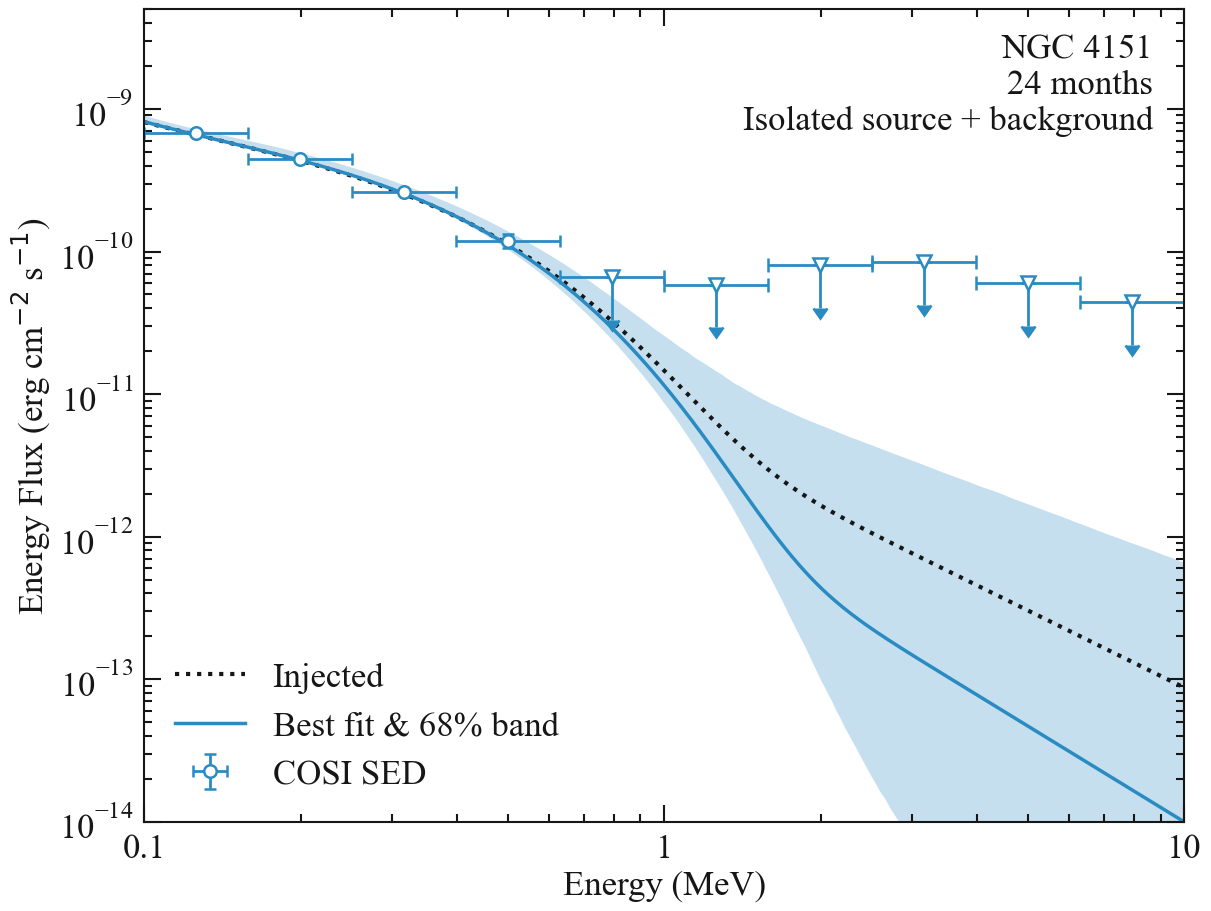

In [28]:
def plot_isolated_cpl_pl(result):
    sed = result["sed"]
    pivot = np.asarray(sed["pivot keV"])
    edges = np.asarray(sed["edges keV"])
    detected = ((sed["TS"] >= SED_DETECTION_TS) & (sed["K"] > 0.) &
                (sed["lower 68"] > 0.) & np.isfinite(sed["upper 68"]))
    upper = (~detected) & np.isfinite(sed["upper 95"]) & (sed["upper 95"] > 0.)
    plot_energy = PLOT_ENERGY_KEV
    x = plot_energy / 1000.
    fitted = result["shape"]
    with paper_style("light", FONT_SIZE):
        fig, ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
        style_axis(ax, "light", FONT_SIZE)
        injected = np.asarray([spectrum_inj_isolated.evaluate_at(e) for e in plot_energy])
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * injected, color=ink("light"),
                ls=":", lw=3, label="Injected")
        best = np.asarray([fitted.evaluate_at(e) for e in plot_energy])
        ax.plot(x, KEV_TO_ERG * plot_energy**2 * best, color=BLUE, lw=2.5,
                label="Best fit & 68% band")
        ax.fill_between(energy/1000.,
                        KEV_TO_ERG * energy**2 * np.where(result["low"] > 0, result["low"], np.nan),
                        KEV_TO_ERG * energy**2 * np.where(result["high"] > 0, result["high"], np.nan),
                        color=BLUE, alpha=0.27, linewidth=0)
        if np.any(detected):
            p = pivot[detected]
            k = sed["K"][detected]
            ax.errorbar(p/1000., KEV_TO_ERG*p**2*k,
                        xerr=np.vstack((p-edges[:-1][detected], edges[1:][detected]-p))/1000.,
                        yerr=np.vstack((KEV_TO_ERG*p**2*(k-sed["lower 68"][detected]),
                                        KEV_TO_ERG*p**2*(sed["upper 68"][detected]-k))),
                        fmt="o", color=BLUE, ecolor=BLUE, markerfacecolor="white",
                        markeredgewidth=1.8, markersize=9, capsize=4,
                        label="COSI SED")
        if np.any(upper):
            p = pivot[upper]
            limits = KEV_TO_ERG*p**2*sed["upper 95"][upper]
            ax.errorbar(p/1000., limits,
                        xerr=np.vstack((p-edges[:-1][upper], edges[1:][upper]-p))/1000.,
                        yerr=np.maximum(0.5*limits, np.finfo(float).tiny), uplims=True,
                        fmt="v", color=BLUE, ecolor=BLUE, markerfacecolor="white",
                        markeredgewidth=1.8, markersize=10, capsize=5)
        visible = np.r_[KEV_TO_ERG*pivot[upper]**2*sed["upper 95"][upper],
                        KEV_TO_ERG*pivot[detected]**2*sed["K"][detected]]
        ax.set(xscale="log", yscale="log", xlim=(0.1, 10.),
               ylim=(max(1e-14, 0.0001*np.min(visible)) if visible.size else 1e-14,
                     max(5e-9, 2*np.max(visible)) if visible.size else 1e-9),
               xlabel="Energy (MeV)", ylabel=r"Energy Flux (erg cm$^{-2}$ s$^{-1}$)")
        ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 1., 10.]))
        ax.xaxis.set_major_formatter(mticker.FixedFormatter(["0.1", "1", "10"]))
        ax.text(0.97, 0.97, "NGC 4151\n24 months\nIsolated source + background",
                transform=ax.transAxes, ha="right", va="top", fontsize=FONT_SIZE,
                color=ink("light"), bbox=dict(facecolor="white", edgecolor="none",
                                              alpha=0.78, pad=5))
        ax.legend(loc="lower left", frameon=False, fontsize=FONT_SIZE)
        PAPER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        pdf_path = PAPER_OUTPUT_DIR / "NGC4151_DC4_paper_isolated_cpl_pl_24months_white.pdf"
        png_path = PAPER_OUTPUT_DIR / "NGC4151_DC4_paper_isolated_cpl_pl_24months_white.png"
        fig.savefig(pdf_path, format="pdf", facecolor="white", edgecolor="white",
                    transparent=False, bbox_inches="tight")
        fig.savefig(png_path, dpi=220, facecolor="white", edgecolor="white",
                    transparent=False, bbox_inches="tight")
        print("Saved", pdf_path, "and", png_path)
        plt.show()
    return fig

isolated_figure = plot_isolated_cpl_pl(isolated_result)
